# Этап 1 — Подготовка данных: хранилище PostgreSQL, признаки и KPI

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Исследование начинается не с готового набора данных, а с **постановки задачи**, определения **KPI** и **признаков**, которые нужны для её решения, и с построения **хранилища данных (DWH)**, из которого обучающий набор получается **SQL-запросом**.

| Шаг | Что делается | Где |
|---|---|---|
| 1 | Цель, KPI и необходимые признаки | этот ноутбук, раздел 1 |
| 2 | **Extract**: загрузка данных из API Open-Meteo в зону приёма (landing) | `src/download_data.py` → `data/raw/` |
| 3 | **Load**: массовая загрузка в промежуточную зону (staging) командой `COPY` | `src/etl_postgres.py` → `stg.open_meteo_daily` |
| 4 | **Transform**: построение схемы «звезда» (измерения + таблица фактов) | `sql/01_schema.sql`, `sql/02_transform.sql` → схема `dwh` |
| 5 | Контроль качества и аналитические (OLAP) запросы | этот ноутбук, разделы 5–6 |
| 6 | **Запрос, формирующий обучающий набор** | `sql/03_dataset.sql` |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import query, sql_file, load_dataset, DATABASE_URL
from etl_postgres import run_etl
from features import build_features, FEATURES, TARGET, TARGET3, WEATHER_TYPES

FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.max_colwidth", 120, "display.width", 160)

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

print(f"Хранилище: {DATABASE_URL}")
print(query("SELECT version()").iloc[0, 0])

Хранилище: postgresql+psycopg:///sad_weather
PostgreSQL 17.11 (Homebrew) on aarch64-apple-darwin24.6.0, compiled by Apple clang version 17.0.0 (clang-1700.6.4.2), 64-bit


---
## 1. Цель задачи, KPI и необходимые признаки

**Проблема.** Неблагоприятная погода (осадки, сильный ветер, жара, мороз) мешает сельскому хозяйству, транспорту, мероприятиям и работе экстренных служб. Решения о планировании принимаются накануне, поэтому нужен **прогноз на завтра**, понятный и проверяемый.

**Цель.** Построить систему, которая по сегодняшним метеоданным станции Кишинёв предсказывает:
1. будут ли завтра **осадки ≥ 1 мм** (бинарная задача — основная);
2. **тип погоды** завтра: благоприятная / неблагоприятная / критическая (3 класса — для предупреждений);

и работает в режиме **реального времени** с автоматическими уведомлениями.

### 1.1 Ключевые показатели эффективности (KPI)

KPI задаются **до** моделирования и делятся на две группы: KPI **данных** (проверяются на этом этапе) и KPI **модели** (проверяются в ноутбуке 02 на тестовых 2024–2025 годах).

In [2]:
kpi_data = pd.DataFrame([
    ("D-1", "Полнота данных", "доля дней с наблюдениями от календарных дней, по каждой станции", "≥ 99 %",
     "без пропусков нельзя считать лаги и тренды"),
    ("D-2", "Корректность данных", "доля строк, прошедших ограничения CHECK (физические правила)", "100 %",
     "невозможные значения искажают модель"),
    ("D-3", "Уникальность", "дубликаты ключа (станция, дата)", "0",
     "дубликат = двойной вес дня при обучении"),
    ("D-4", "Географический охват", "число станций из разных регионов страны", "≥ 5",
     "нужно для проверки справедливости (Bias)"),
    ("D-5", "Глубина истории", "число лет наблюдений", "≥ 10",
     "сезонность и межгодовая изменчивость"),
], columns=["Код", "KPI данных", "Как считается", "Цель", "Зачем"])
kpi_model = pd.DataFrame([
    ("KPI-1", "Различающая способность", "ROC-AUC", "≥ 0.75", "модель должна ранжировать дни по риску"),
    ("KPI-2", "Обнаружение дней с осадками", "Recall", "≥ 0.70", "пропущенный дождь дороже ложной тревоги"),
    ("KPI-3", "Качество тревог для редкого класса", "PR-AUC", "≥ 2 × частота класса", "классы несбалансированы"),
    ("KPI-4", "Польза относительно наивного прогноза", "F1 − F1 инерционности", "≥ +0.05", "модель должна быть лучше «завтра как сегодня»"),
    ("KPI-5", "Качество вероятностей", "Brier skill score vs. климатология", "> 0", "вероятности используются для решений"),
    ("KPI-6", "Доля ложных тревог", "1 − Precision", "≤ 0.60", "слишком много тревог — им перестают верить"),
    ("KPI-7", "Стабильность по сезонам", "минимальный ROC-AUC по сезонам", "≥ 0.70", "прогноз нужен круглый год"),
], columns=["Код", "KPI модели", "Метрика", "Цель", "Зачем"])
display(kpi_data); display(kpi_model)

,Код,KPI данных,Как считается,Цель,Зачем
0,D-1,Полнота данных,"доля дней с наблюдениями от календарных дней, по каждой станции",≥ 99 %,без пропусков нельзя считать лаги и тренды
1,D-2,Корректность данных,"доля строк, прошедших ограничения CHECK (физические правила)",100 %,невозможные значения искажают модель
2,D-3,Уникальность,"дубликаты ключа (станция, дата)",0,дубликат = двойной вес дня при обучении
3,D-4,Географический охват,число станций из разных регионов страны,≥ 5,нужно для проверки справедливости (Bias)
4,D-5,Глубина истории,число лет наблюдений,≥ 10,сезонность и межгодовая изменчивость


,Код,KPI модели,Метрика,Цель,Зачем
0,KPI-1,Различающая способность,ROC-AUC,≥ 0.75,модель должна ранжировать дни по риску
1,KPI-2,Обнаружение дней с осадками,Recall,≥ 0.70,пропущенный дождь дороже ложной тревоги
2,KPI-3,Качество тревог для редкого класса,PR-AUC,≥ 2 × частота класса,классы несбалансированы
3,KPI-4,Польза относительно наивного прогноза,F1 − F1 инерционности,≥ +0.05,модель должна быть лучше «завтра как сегодня»
4,KPI-5,Качество вероятностей,Brier skill score vs. климатология,> 0,вероятности используются для решений
5,KPI-6,Доля ложных тревог,1 − Precision,≤ 0.60,слишком много тревог — им перестают верить
6,KPI-7,Стабильность по сезонам,минимальный ROC-AUC по сезонам,≥ 0.70,прогноз нужен круглый год


### 1.2 Какие данные и признаки нужны для достижения цели

Осадки формируются при **влажном воздухе**, **подъёме воздуха** (фронты, циклоны — падение давления) и **приток влаги** (направление ветра). Поэтому из хранилища нужны:

| Группа | Измерения в хранилище | Признаки для модели | Почему |
|---|---|---|---|
| Давление | `pressure_msl_mean/max/min` | давление, его изменение за 1 и 3 дня, колебание за день | падение давления — признак приближения фронта |
| Влажность | `relative_humidity_*`, `dew_point_2m_mean`, `vapour_pressure_deficit_max` | влажность, точка росы, дефицит точки росы, изменение влажности | насыщенный воздух — условие осадков |
| Облачность и солнце | `cloud_cover_mean`, `sunshine_duration`, `daylight_duration` | облачность сегодня и вчера, доля солнечного сияния | облачность предшествует осадкам |
| Осадки | `precipitation_sum`, `precipitation_hours`, `snowfall_sum` | осадки сегодня, за 3 дня, число дождливых дней за 7 | «память» погоды (инерционность) |
| Ветер | `wind_speed_10m_max`, `wind_direction_10m_dominant` | скорость, направление (sin, cos) | ветер с В–Ю приносит влагу с Чёрного моря |
| Температура | `temperature_2m_*` | средняя температура, суточная амплитуда | конвекция, тип осадков |
| Почва | `soil_moisture_0_to_7cm_mean` | влажность почвы | испарение, локальная влажность |
| Календарь | `dim_date.day_of_year` | день года (sin, cos) | сезонность |
| Цель | `precipitation_sum`, порывы, T_max/T_min, снег **следующего** дня | `rain_tomorrow`, `weather_type_tomorrow` | то, что предсказываем |

---
## 2. Источник данных и архитектура ETL

**Источник:** архив Open-Meteo (реанализ ERA5 Европейского центра среднесрочных прогнозов ECMWF), суточные данные 2015–2025, **6 станций (узлов сетки)** — Кишинёв и по одному пункту из каждого региона Молдовы.
**Extract** выполнен скриптом `src/download_data.py` (HTTP API, с повторами при ограничении частоты запросов); ответы сохранены в зоне приёма `data/raw/` — это неизменяемая копия источника.

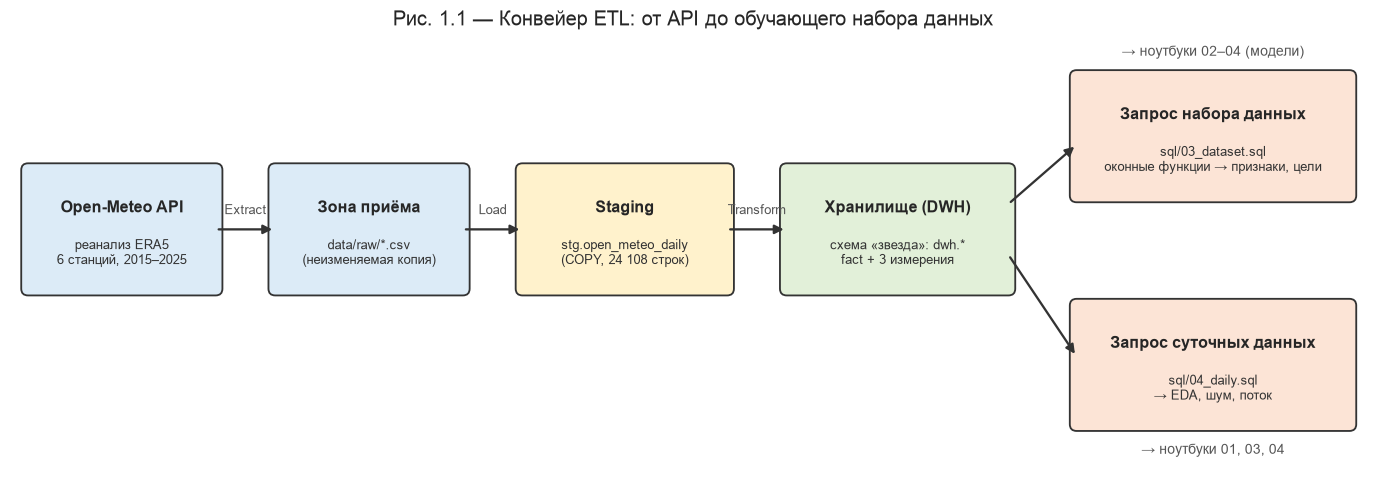

In [3]:
fig, ax = plt.subplots(figsize=(16, 5.2)); ax.set_xlim(0, 16); ax.set_ylim(0, 5.2); ax.axis("off")
def box(x, y, w, h, title, sub, color):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="#333", lw=1.2))
    ax.text(x + w / 2, y + h * 0.68, title, ha="center", va="center", fontsize=10.5, fontweight="bold")
    ax.text(x + w / 2, y + h * 0.3, sub, ha="center", va="center", fontsize=8.5, color="#333")
def arrow(x1, y1, x2, y2, text=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#333"))
    if text: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.18, text, ha="center", fontsize=8.5, color="#555")
box(0.2, 2.2, 2.2, 1.4, "Open-Meteo API", "реанализ ERA5\n6 станций, 2015–2025", "#DCEBF7")
box(3.1, 2.2, 2.2, 1.4, "Зона приёма", "data/raw/*.csv\n(неизменяемая копия)", "#DCEBF7")
box(6.0, 2.2, 2.4, 1.4, "Staging", "stg.open_meteo_daily\n(COPY, 24 108 строк)", "#FFF2CC")
box(9.1, 2.2, 2.6, 1.4, "Хранилище (DWH)", "схема «звезда»: dwh.*\nfact + 3 измерения", "#E2F0D9")
box(12.5, 3.3, 3.2, 1.4, "Запрос набора данных", "sql/03_dataset.sql\nоконные функции → признаки, цели", "#FCE4D6")
box(12.5, 0.6, 3.2, 1.4, "Запрос суточных данных", "sql/04_daily.sql\n→ EDA, шум, поток", "#FCE4D6")
arrow(2.4, 2.9, 3.1, 2.9, "Extract"); arrow(5.3, 2.9, 6.0, 2.9, "Load")
arrow(8.4, 2.9, 9.1, 2.9, "Transform"); arrow(11.7, 3.2, 12.5, 3.9); arrow(11.7, 2.6, 12.5, 1.4)
ax.text(14.1, 4.95, "→ ноутбуки 02–04 (модели)", ha="center", fontsize=9, color="#555")
ax.text(14.1, 0.25, "→ ноутбуки 01, 03, 04", ha="center", fontsize=9, color="#555")
ax.set_title("Рис. 1.1 — Конвейер ETL: от API до обучающего набора данных", fontsize=13)
save("fig_1_1_etl_architecture")

---
## 3. Схема хранилища «звезда»

**Зерно таблицы фактов:** одна строка = одна станция × один день.

| Таблица | Тип | Содержание |
|---|---|---|
| `dwh.fact_weather_daily` | факты | 26 метеоизмерений + внешние ключи; ограничения `CHECK` проверяют физическую корректность при загрузке |
| `dwh.dim_station` | измерение | станция: название, регион, запрошенные координаты и координаты узла ERA5, высота, признак эталонной станции |
| `dwh.dim_date` | измерение | дата: год, квартал, месяц, день года, неделя, сезон, выходной |
| `dwh.dim_weather_code` | измерение | код погоды ВМО: описание и группа явлений |

In [4]:
cols = query('''
    SELECT table_schema || '.' || table_name AS tbl, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema IN ('dwh', 'stg')
    ORDER BY table_schema, table_name, ordinal_position''')
summary = cols.groupby("tbl").agg(**{"Столбцов": ("column_name", "size")})
keys = query('''
    SELECT tc.table_schema || '.' || tc.table_name AS tbl, tc.constraint_type AS kind, COUNT(*) AS n
    FROM information_schema.table_constraints tc
    WHERE tc.table_schema = 'dwh' AND tc.constraint_type IN ('PRIMARY KEY', 'FOREIGN KEY', 'CHECK', 'UNIQUE')
      AND tc.constraint_name NOT LIKE '%%not_null%%'
    GROUP BY 1, 2''').pivot(index="tbl", columns="kind", values="n").fillna(0).astype(int)
summary.join(keys).fillna(0).astype(int)

,Столбцов,CHECK,FOREIGN KEY,PRIMARY KEY,UNIQUE
tbl,,,,,
dwh.dim_date,11,0,0,1,1
dwh.dim_station,10,0,0,1,1
dwh.dim_weather_code,3,0,0,1,0
dwh.fact_weather_daily,28,14,3,1,0
stg.open_meteo_daily,30,0,0,0,0


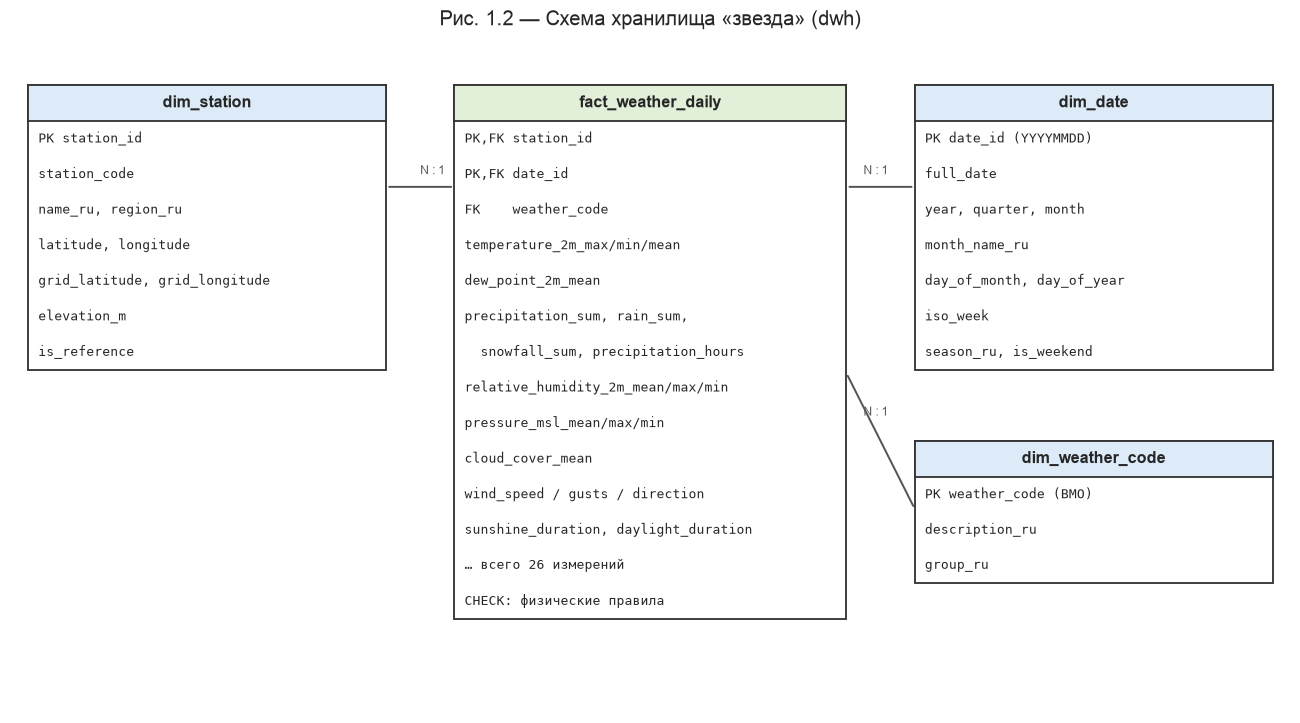

In [5]:
fig, ax = plt.subplots(figsize=(15, 8)); ax.set_xlim(0, 15); ax.set_ylim(0, 8); ax.axis("off")
def table(x, y, w, title, rows, color):
    h = 0.42 * (len(rows) + 1)
    ax.add_patch(mpatches.Rectangle((x, y - h), w, h, fc="white", ec="#333", lw=1.2))
    ax.add_patch(mpatches.Rectangle((x, y - 0.42), w, 0.42, fc=color, ec="#333", lw=1.2))
    ax.text(x + w / 2, y - 0.21, title, ha="center", va="center", fontsize=10.5, fontweight="bold")
    for i, r in enumerate(rows):
        ax.text(x + 0.12, y - 0.42 * (i + 1.5), r, va="center", fontsize=8.6, family="monospace")
    return (x, y - h, w, h)
fact = table(5.2, 7.4, 4.6, "fact_weather_daily", [
    "PK,FK station_id", "PK,FK date_id", "FK    weather_code", "temperature_2m_max/min/mean",
    "dew_point_2m_mean", "precipitation_sum, rain_sum,", "  snowfall_sum, precipitation_hours",
    "relative_humidity_2m_mean/max/min", "pressure_msl_mean/max/min", "cloud_cover_mean",
    "wind_speed / gusts / direction", "sunshine_duration, daylight_duration", "… всего 26 измерений",
    "CHECK: физические правила"], "#E2F0D9")
st = table(0.2, 7.4, 4.2, "dim_station", [
    "PK station_id", "station_code", "name_ru, region_ru", "latitude, longitude",
    "grid_latitude, grid_longitude", "elevation_m", "is_reference"], "#DCEBF7")
dt = table(10.6, 7.4, 4.2, "dim_date", [
    "PK date_id (YYYYMMDD)", "full_date", "year, quarter, month", "month_name_ru",
    "day_of_month, day_of_year", "iso_week", "season_ru, is_weekend"], "#DCEBF7")
wc = table(10.6, 3.2, 4.2, "dim_weather_code", ["PK weather_code (ВМО)", "description_ru", "group_ru"], "#DCEBF7")
for (x2, y2) in [(4.4, 6.2), (10.6, 6.2), (10.6, 2.4)]:
    x1 = 5.2 if x2 < 5.2 else 9.8
    ax.annotate("", xy=(x2, y2), xytext=(x1, y2 if y2 > 5 else 4.0), arrowprops=dict(arrowstyle="-", lw=1.3, color="#555"))
ax.text(4.8, 6.35, "N : 1", fontsize=8, color="#555"); ax.text(10.0, 6.35, "N : 1", fontsize=8, color="#555")
ax.text(10.0, 3.5, "N : 1", fontsize=8, color="#555")
ax.set_title("Рис. 1.2 — Схема хранилища «звезда» (dwh)", fontsize=13)
save("fig_1_2_star_schema")

---
## 4. Запуск ETL

Скрипт `src/etl_postgres.py`: создаёт схемы (`sql/01_schema.sql`), загружает файлы зоны приёма в staging командой `COPY`, заполняет `dim_station` и выполняет преобразование в «звезду» (`sql/02_transform.sql`). Скрипт идемпотентен — его можно запускать повторно.

In [6]:
counts = run_etl()
counts

1. Schema created: stg, dwh
2. Staging: chisinau  ← data/raw/chisinau_daily_2015_2025.csv (4018 rows)
2. Staging: soroca    ← data/raw/cities/soroca_daily_2015_2025.csv (4018 rows)
2. Staging: balti     ← data/raw/cities/balti_daily_2015_2025.csv (4018 rows)
2. Staging: ungheni   ← data/raw/cities/ungheni_daily_2015_2025.csv (4018 rows)
2. Staging: comrat    ← data/raw/cities/comrat_daily_2015_2025.csv (4018 rows)
2. Staging: cahul     ← data/raw/cities/cahul_daily_2015_2025.csv (4018 rows)
3. dim_station filled


4. Transform done in 0.5 s


,Таблица,Строк
0,dwh.dim_station,6
1,dwh.dim_weather_code,28
2,dwh.dim_date,4018
3,dwh.fact_weather_daily,24108
4,stg.open_meteo_daily,24108


**Фрагмент преобразования** `sql/02_transform.sql` (заполнение таблицы фактов из staging):

In [7]:
t = sql_file("02_transform.sql")
print(t[t.index("-- ------------------------------------------------------------------ fact_weather_daily"):t.index("ANALYZE")].strip())

-- ------------------------------------------------------------------ fact_weather_daily
INSERT INTO dwh.fact_weather_daily
SELECT  s.station_id,
        TO_CHAR(g.date, 'YYYYMMDD')::INT,
        g.weather_code,
        g.temperature_2m_max, g.temperature_2m_min, g.temperature_2m_mean,
        g.apparent_temperature_mean, g.dew_point_2m_mean,
        g.precipitation_sum, g.rain_sum, g.snowfall_sum, g.precipitation_hours,
        g.relative_humidity_2m_mean, g.relative_humidity_2m_max, g.relative_humidity_2m_min,
        g.pressure_msl_mean, g.pressure_msl_max, g.pressure_msl_min,
        g.cloud_cover_mean,
        g.wind_speed_10m_max, g.wind_gusts_10m_max, g.wind_direction_10m_dominant,
        g.shortwave_radiation_sum, g.sunshine_duration, g.daylight_duration,
        g.et0_fao_evapotranspiration, g.vapour_pressure_deficit_max, g.soil_moisture_0_to_7cm_mean
FROM stg.open_meteo_daily g
JOIN dwh.dim_station s ON s.station_code = g.station_code;


---
## 5. Контроль качества данных (SQL)

Проверяем KPI данных D-1 … D-5 запросами к хранилищу.

In [8]:
quality = query('''
    WITH expected AS (SELECT COUNT(*) AS days FROM dwh.dim_date)
    SELECT  s.name_ru                                                        AS "Станция",
            s.region_ru                                                      AS "Регион",
            COUNT(f.*)                                                       AS "Дней с данными",
            ROUND(100.0 * COUNT(f.*) / MAX(e.days), 2)                       AS "Полнота, %%",
            SUM(CASE WHEN f.precipitation_sum IS NULL OR f.pressure_msl_mean IS NULL
                          OR f.temperature_2m_mean IS NULL THEN 1 ELSE 0 END) AS "Строк с NULL",
            MIN(d.full_date)                                                 AS "С",
            MAX(d.full_date)                                                 AS "По"
    FROM    dwh.dim_station s
    CROSS JOIN expected e
    LEFT JOIN dwh.fact_weather_daily f ON f.station_id = s.station_id
    LEFT JOIN dwh.dim_date d           ON d.date_id    = f.date_id
    GROUP BY s.station_id, s.name_ru, s.region_ru
    ORDER BY s.station_id''')
quality

,Станция,Регион,Дней с данными,"Полнота, %",Строк с NULL,С,По
0,Кишинёв,Центр,4018,100.0,0,2015-01-01,2025-12-31
1,Сороки,Север (Днестр),4018,100.0,0,2015-01-01,2025-12-31
2,Бельцы,Север,4018,100.0,0,2015-01-01,2025-12-31
3,Унгены,Запад (Прут),4018,100.0,0,2015-01-01,2025-12-31
4,Комрат,Юг (Гагаузия),4018,100.0,0,2015-01-01,2025-12-31
5,Кагул,Юго-запад,4018,100.0,0,2015-01-01,2025-12-31


In [9]:
checks = query('''
    SELECT 'Дубликаты ключа (станция, дата)' AS "Проверка",
           (SELECT COUNT(*) FROM (SELECT station_id, date_id FROM dwh.fact_weather_daily
                                  GROUP BY 1, 2 HAVING COUNT(*) > 1) x) AS "Нарушений"
    UNION ALL
    SELECT 'Коды погоды без описания в измерении',
           (SELECT COUNT(*) FROM stg.open_meteo_daily g
             LEFT JOIN dwh.dim_weather_code w USING (weather_code) WHERE w.weather_code IS NULL)
    UNION ALL
    SELECT 'Строк staging, не попавших в факты',
           (SELECT COUNT(*) FROM stg.open_meteo_daily) - (SELECT COUNT(*) FROM dwh.fact_weather_daily)
    UNION ALL
    SELECT 'Пропущенные дни внутри ряда (разрыв дат)',
           (SELECT COUNT(*) FROM (SELECT d.full_date - LAG(d.full_date) OVER (PARTITION BY f.station_id ORDER BY d.full_date) AS gap
                                  FROM dwh.fact_weather_daily f JOIN dwh.dim_date d USING (date_id)) g WHERE gap > 1)
    UNION ALL
    SELECT 'Ограничений CHECK в таблице фактов (все выполнены при загрузке)',
           (SELECT COUNT(DISTINCT c.constraint_name) FROM information_schema.check_constraints c
             JOIN information_schema.constraint_column_usage u USING (constraint_schema, constraint_name)
             WHERE u.table_schema = 'dwh' AND u.table_name = 'fact_weather_daily'
               AND c.constraint_name NOT LIKE '%%not_null%%')''')
checks

,Проверка,Нарушений
0,"Дубликаты ключа (станция, дата)",0
1,Коды погоды без описания в измерении,0
2,"Строк staging, не попавших в факты",0
3,Пропущенные дни внутри ряда (разрыв дат),0
4,Ограничений CHECK в таблице фактов (все выполнены при загрузке),14


**Интерпретация.** Все 6 станций имеют **100 %** календарных дней (KPI D-1 выполнен), пропусков внутри рядов и дубликатов ключа нет (D-3), все коды погоды есть в измерении, все строки staging перешли в факты. Физические правила заданы **ограничениями `CHECK`** на уровне базы: строка, нарушающая их (например, влажность > 100 % или T_min > T_max), была бы отклонена при загрузке — так как загрузка прошла без ошибок, корректность данных 100 % (D-2). Охват — 6 станций из всех регионов (D-4), история — 11 лет (D-5).

---
## 6. Аналитические (OLAP) запросы к хранилищу

Схема «звезда» позволяет быстро отвечать на аналитические вопросы срезами по измерениям. Эти ответы обосновывают выбор признаков и KPI.

### 6.1 Частота дней с осадками: станция × сезон

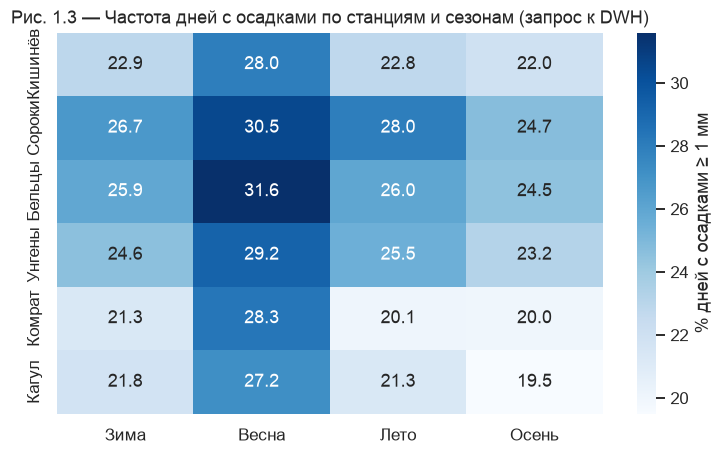

season,Зима,Весна,Лето,Осень
station,,,,
Кишинёв,22.9,28.0,22.8,22.0
Сороки,26.7,30.5,28.0,24.7
Бельцы,25.9,31.6,26.0,24.5
Унгены,24.6,29.2,25.5,23.2
Комрат,21.3,28.3,20.1,20.0
Кагул,21.8,27.2,21.3,19.5


In [10]:
rain_freq = query('''
    SELECT  s.name_ru AS station, d.season_ru AS season,
            ROUND(100.0 * AVG((f.precipitation_sum >= 1)::INT), 1) AS rain_pct
    FROM    dwh.fact_weather_daily f
    JOIN    dwh.dim_station s USING (station_id)
    JOIN    dwh.dim_date d    USING (date_id)
    GROUP BY s.station_id, s.name_ru, d.season_ru
    ORDER BY s.station_id''')
pv = rain_freq.pivot(index="station", columns="season", values="rain_pct")
pv = pv.loc[rain_freq.station.unique(), ["Зима", "Весна", "Лето", "Осень"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% дней с осадками ≥ 1 мм"}, ax=ax)
ax.set(xlabel="", ylabel="", title="Рис. 1.3 — Частота дней с осадками по станциям и сезонам (запрос к DWH)")
save("fig_1_3_rain_frequency")
pv

### 6.2 Критические дни по станциям и причинам (агрегаты с `FILTER`)

In [11]:
query('''
    SELECT  s.name_ru                                                            AS "Станция",
            COUNT(*) FILTER (WHERE f.precipitation_sum   >= 10)                  AS "Осадки ≥ 10 мм",
            COUNT(*) FILTER (WHERE f.wind_gusts_10m_max  >= 60)                  AS "Порывы ≥ 60 км/ч",
            COUNT(*) FILTER (WHERE f.temperature_2m_max  >= 35)                  AS "Жара ≥ 35 °C",
            COUNT(*) FILTER (WHERE f.temperature_2m_min  <= -15)                 AS "Мороз ≤ −15 °C",
            COUNT(*) FILTER (WHERE f.snowfall_sum        >= 5)                   AS "Снег ≥ 5 см",
            COUNT(*) FILTER (WHERE f.precipitation_sum >= 10 OR f.wind_gusts_10m_max >= 60
                                OR f.temperature_2m_max >= 35 OR f.temperature_2m_min <= -15
                                OR f.snowfall_sum >= 5)                          AS "Критических дней",
            ROUND(100.0 * COUNT(*) FILTER (WHERE f.precipitation_sum >= 10 OR f.wind_gusts_10m_max >= 60
                                OR f.temperature_2m_max >= 35 OR f.temperature_2m_min <= -15
                                OR f.snowfall_sum >= 5) / COUNT(*), 1)           AS "%% дней"
    FROM    dwh.fact_weather_daily f
    JOIN    dwh.dim_station s USING (station_id)
    GROUP BY s.station_id, s.name_ru
    ORDER BY s.station_id''')

,Станция,Осадки ≥ 10 мм,Порывы ≥ 60 км/ч,Жара ≥ 35 °C,Мороз ≤ −15 °C,Снег ≥ 5 см,Критических дней,% дней
0,Кишинёв,149,93,25,12,19,271,6.7
1,Сороки,142,90,27,16,17,276,6.9
2,Бельцы,155,87,23,19,18,279,6.9
3,Унгены,158,77,21,19,24,277,6.9
4,Комрат,148,79,43,10,16,264,6.6
5,Кагул,144,75,28,9,19,244,6.1


### 6.3 Годовые суммы осадков с итогами (`GROUP BY ROLLUP`), Кишинёв

In [12]:
query('''
    SELECT  COALESCE(d.year::TEXT, 'Итого за 2015–2025')  AS "Год",
            ROUND(SUM(f.precipitation_sum)::NUMERIC, 0)     AS "Осадки, мм",
            COUNT(*) FILTER (WHERE f.precipitation_sum >= 1) AS "Дней с осадками",
            ROUND(AVG(f.temperature_2m_mean)::NUMERIC, 2)   AS "Средняя T, °C"
    FROM    dwh.fact_weather_daily f
    JOIN    dwh.dim_station s USING (station_id)
    JOIN    dwh.dim_date d    USING (date_id)
    WHERE   s.is_reference
    GROUP BY ROLLUP (d.year)
    ORDER BY d.year NULLS LAST''')

,Год,"Осадки, мм",Дней с осадками,"Средняя T, °C"
0,2015,475.0,84,12.33
1,2016,613.0,88,11.70
2,2017,592.0,87,11.03
3,2018,492.0,84,11.18
4,2019,414.0,86,12.07
5,2020,489.0,90,12.34
6,2021,598.0,115,10.26
7,2022,450.0,79,11.43
8,2023,531.0,87,12.64
9,2024,581.0,85,12.77


### 6.4 Распределение типов погоды по группам кодов ВМО (соединение с измерением `dim_weather_code`)

In [13]:
query('''
    SELECT  w.group_ru                                         AS "Группа явлений",
            COUNT(*)                                           AS "Дней",
            ROUND(AVG(f.precipitation_sum)::NUMERIC, 2)        AS "Средние осадки, мм",
            ROUND(AVG(f.pressure_msl_mean)::NUMERIC, 1)        AS "Среднее давление, гПа",
            ROUND(AVG(f.cloud_cover_mean)::NUMERIC, 0)         AS "Средняя облачность, %%"
    FROM    dwh.fact_weather_daily f
    JOIN    dwh.dim_weather_code w USING (weather_code)
    JOIN    dwh.dim_station s      USING (station_id)
    WHERE   s.is_reference
    GROUP BY w.group_ru
    ORDER BY "Средние осадки, мм"''')

,Группа явлений,Дней,"Средние осадки, мм","Среднее давление, гПа","Средняя облачность, %"
0,Без осадков,2221,0.00,1019.2,45.0
1,Морось,1110,1.14,1014.3,67.0
2,Снег,305,3.35,1017.2,84.0
3,Дождь,382,8.87,1010.9,75.0


**Интерпретация.**
- Частота дней с осадками различается по станциям и сезонам: на всех станциях максимум **весной** (27–32 %); юг (Комрат, Кагул) засушливее севера (Сороки, Бельцы), особенно летом и осенью (Комрат летом 20 % против 28 % в Сороках). Это обосновывает **KPI-7** (стабильность по сезонам) и проверку **географической справедливости** (элемент Bias).
- Критические дни составляют 6–7 % на всех станциях и в основном вызваны сильными осадками и ветром; на юге (Комрат) заметно больше дней жары (43 против 21–28). Класс редкий — отсюда **KPI-3** (PR-AUC) и необходимость **SMOTE**.
- Дни с осадками (группы «Дождь», «Морось», «Снег») идут при более низком давлении и большей облачности, чем дни «Без осадков», — это подтверждает выбор признаков давления и облачности (раздел 1.2).

---
## 7. Запрос, формирующий обучающий набор данных

Это **главный запрос этапа 1** (`sql/03_dataset.sql`): из таблицы фактов и измерений он строит все 26 признаков и обе целевые переменные с помощью **оконных функций**:
- `LAG(...) OVER w` — значения предыдущих дней (изменение давления, вчерашняя облачность);
- `SUM(...) OVER (w ROWS BETWEEN k PRECEDING AND CURRENT ROW)` — скользящие суммы (осадки за 3 дня, дождливые дни за 7);
- `LEAD(...) OVER w` — значения **следующего** дня, т. е. целевые переменные;
- `CASE` — тип погоды по критериям критичности.

Все признаки используют только сегодняшний и прошлые дни — утечки информации из будущего нет; будущее (`LEAD`) используется только для целевых переменных.

In [14]:
print(sql_file("03_dataset.sql"))

-- =====================================================================================
-- 03_dataset.sql — THE query that produces the modelling dataset from the data warehouse
--
-- For one station it returns, per day t:
--   * 26 features computed from day t and the preceding days only (window functions LAG / SUM OVER),
--   * the targets for day t+1 (window function LEAD):
--       rain_tomorrow          — precipitation on day t+1 >= 1 mm (0/1),
--       weather_type_tomorrow  — 0 favourable / 1 unfavourable / 2 critical weather on day t+1.
-- Days without 6 days of history (first rows) and the last day (no "tomorrow") are excluded.
-- Parameter: %(station_code)s, e.g. 'chisinau'.
-- =====================================================================================
WITH daily AS (
    SELECT  d.full_date                                  AS date,
            d.day_of_year,
            f.*,
            -- weather type of the day (thresholds: see src/features.py)
            CASE 

In [15]:
dataset = load_dataset("chisinau")
print(f"Набор данных: {dataset.shape[0]} строк x {dataset.shape[1]} столбцов, "
      f"{dataset.date.min().date()} — {dataset.date.max().date()}")
print(f"Доля дней «дождь завтра»: {dataset[TARGET].mean():.1%}")
print("Типы погоды завтра:", dataset[TARGET3].value_counts().sort_index().rename(dict(enumerate(WEATHER_TYPES))).to_dict())
dataset.head()

Набор данных: 4011 строк x 29 столбцов, 2015-01-07 — 2025-12-30
Доля дней «дождь завтра»: 23.9%
Типы погоды завтра: {'Благоприятная': 2238, 'Неблагоприятная': 1502, 'Критическая': 271}


,date,temperature_2m_mean,temp_range,dew_point_2m_mean,dew_point_depression,relative_humidity_2m_mean,relative_humidity_2m_max,pressure_msl_mean,pressure_intraday_range,cloud_cover_mean,...,pressure_change_1d,pressure_change_3d,cloud_cover_lag1,humidity_change_1d,precip_sum_3d,precip_days_7d,doy_sin,doy_cos,rain_tomorrow,weather_type_tomorrow
0,2015-01-07,-10.6,5.0,-16.5,5.9,62.0,74.0,1031.6,13.0,60.0,...,14.6,22.7,54.0,-12.0,2.7,2.0,0.120126,0.992759,0,2
1,2015-01-08,-12.6,7.5,-16.9,4.3,71.0,78.0,1038.5,4.3,18.0,...,6.9,28.3,60.0,9.0,0.7,2.0,0.137185,0.990545,1,1
2,2015-01-09,-7.7,13.7,-10.9,3.2,78.0,83.0,1022.6,23.7,76.0,...,-15.9,5.6,18.0,7.0,1.8,2.0,0.154204,0.988039,0,1
3,2015-01-10,2.0,5.9,-0.9,2.9,81.0,87.0,1005.2,8.2,91.0,...,-17.4,-26.4,76.0,3.0,2.7,2.0,0.171177,0.985240,1,1
4,2015-01-11,4.2,7.0,1.0,3.2,81.0,92.0,1005.7,6.9,74.0,...,0.5,-32.8,91.0,0.0,6.8,3.0,0.188099,0.982150,1,1


**Проверка.** Признаки, вычисленные запросом в PostgreSQL, сравниваем с признаками, вычисленными на Python (`src/features.py`, тот же код используется в потоковом модуле). Они должны совпадать — иначе модель получала бы в эксплуатации другие признаки, чем при обучении.

In [16]:
raw_csv = pd.read_csv(ROOT / "data" / "raw" / "chisinau_daily_2015_2025.csv", parse_dates=["date"])
py = build_features(raw_csv)
same_rows = len(py) == len(dataset) and (py.date.values == dataset.date.values).all()
max_diff = (py[FEATURES] - dataset[FEATURES]).abs().max()
print(f"Те же дни: {same_rows}")
print(f"Целевые переменные совпадают: {(py[TARGET].values == dataset[TARGET].values).all()} / "
      f"{(py[TARGET3].values == dataset[TARGET3].values).all()}")
print(f"Максимальное расхождение признаков: {max_diff.max():.1e} (признак {max_diff.idxmax()})")

Те же дни: True
Целевые переменные совпадают: True / True
Максимальное расхождение признаков: 1.4e-14 (признак precip_sum_3d)


Расхождение порядка $10^{-14}$ — это погрешность округления чисел с плавающей точкой (pandas считает скользящую сумму накопительно, PostgreSQL — суммирует заново), т. е. результаты **идентичны**. Дальше **все ноутбуки получают данные из хранилища**: ноутбук 02 — этим запросом, ноутбуки 01, 03 и 04 — суточные измерения запросом `sql/04_daily.sql`.

In [17]:
dataset.to_csv(ROOT / "data" / "processed" / "dataset_dwh.csv", index=False)
print("Сохранено: data/processed/dataset_dwh.csv (снимок результата запроса)")

Сохранено: data/processed/dataset_dwh.csv (снимок результата запроса)


---
## 8. Каталог признаков: от столбца хранилища к признаку

In [18]:
catalog = pd.DataFrame([
    ("temperature_2m_mean", "Средняя температура", "f.temperature_2m_mean", "состояние сегодня"),
    ("temp_range", "Суточная амплитуда", "temperature_2m_max − temperature_2m_min", "производный"),
    ("dew_point_2m_mean", "Точка росы", "f.dew_point_2m_mean", "состояние сегодня"),
    ("dew_point_depression", "Дефицит точки росы", "temperature_2m_mean − dew_point_2m_mean", "производный"),
    ("relative_humidity_2m_mean", "Средняя влажность", "f.relative_humidity_2m_mean", "состояние сегодня"),
    ("relative_humidity_2m_max", "Максимальная влажность", "f.relative_humidity_2m_max", "состояние сегодня"),
    ("pressure_msl_mean", "Среднее давление", "f.pressure_msl_mean", "состояние сегодня"),
    ("pressure_intraday_range", "Колебание давления за день", "pressure_msl_max − pressure_msl_min", "производный"),
    ("cloud_cover_mean", "Облачность", "f.cloud_cover_mean", "состояние сегодня"),
    ("sunshine_ratio", "Доля солнечного сияния", "sunshine_duration / daylight_duration", "производный"),
    ("precipitation_sum", "Осадки сегодня", "f.precipitation_sum", "состояние сегодня"),
    ("precipitation_hours", "Часы с осадками", "f.precipitation_hours", "состояние сегодня"),
    ("snowfall_sum", "Снегопад", "f.snowfall_sum", "состояние сегодня"),
    ("wind_speed_10m_max", "Скорость ветра", "f.wind_speed_10m_max", "состояние сегодня"),
    ("wind_dir_sin", "Направление ветра (sin)", "SIN(RADIANS(wind_direction_10m_dominant))", "циклическое кодирование"),
    ("wind_dir_cos", "Направление ветра (cos)", "COS(RADIANS(wind_direction_10m_dominant))", "циклическое кодирование"),
    ("soil_moisture_0_to_7cm_mean", "Влажность почвы", "f.soil_moisture_0_to_7cm_mean", "состояние сегодня"),
    ("vapour_pressure_deficit_max", "Дефицит упругости пара", "f.vapour_pressure_deficit_max", "состояние сегодня"),
    ("pressure_change_1d", "Изменение давления за сутки", "p − LAG(p, 1) OVER w", "оконная функция"),
    ("pressure_change_3d", "Изменение давления за 3 дня", "p − LAG(p, 3) OVER w", "оконная функция"),
    ("cloud_cover_lag1", "Облачность вчера", "LAG(cloud_cover_mean, 1) OVER w", "оконная функция"),
    ("humidity_change_1d", "Изменение влажности", "rh − LAG(rh, 1) OVER w", "оконная функция"),
    ("precip_sum_3d", "Осадки за 3 дня", "SUM(precipitation_sum) OVER (w ROWS 2 PRECEDING)", "оконная функция"),
    ("precip_days_7d", "Дождливых дней за 7", "SUM((precipitation_sum >= 1)::INT) OVER (w ROWS 6 PRECEDING)", "оконная функция"),
    ("doy_sin", "День года (sin)", "SIN(2·π·dim_date.day_of_year / 365.25)", "измерение даты"),
    ("doy_cos", "День года (cos)", "COS(2·π·dim_date.day_of_year / 365.25)", "измерение даты"),
    ("rain_tomorrow", "ЦЕЛЬ: осадки завтра ≥ 1 мм", "(LEAD(precipitation_sum, 1) OVER w >= 1)::INT", "целевая переменная"),
    ("weather_type_tomorrow", "ЦЕЛЬ: тип погоды завтра", "LEAD(CASE … END, 1) OVER w", "целевая переменная"),
], columns=["Признак", "Описание", "Выражение в SQL-запросе", "Происхождение"])
assert set(catalog["Признак"][:-2]) == set(FEATURES)
catalog

,Признак,Описание,Выражение в SQL-запросе,Происхождение
0,temperature_2m_mean,Средняя температура,f.temperature_2m_mean,состояние сегодня
1,temp_range,Суточная амплитуда,temperature_2m_max − temperature_2m_min,производный
2,dew_point_2m_mean,Точка росы,f.dew_point_2m_mean,состояние сегодня
3,dew_point_depression,Дефицит точки росы,temperature_2m_mean − dew_point_2m_mean,производный
4,relative_humidity_2m_mean,Средняя влажность,f.relative_humidity_2m_mean,состояние сегодня
5,relative_humidity_2m_max,Максимальная влажность,f.relative_humidity_2m_max,состояние сегодня
6,pressure_msl_mean,Среднее давление,f.pressure_msl_mean,состояние сегодня
7,pressure_intraday_range,Колебание давления за день,pressure_msl_max − pressure_msl_min,производный
8,cloud_cover_mean,Облачность,f.cloud_cover_mean,состояние сегодня
9,sunshine_ratio,Доля солнечного сияния,sunshine_duration / daylight_duration,производный


---
## 9. Выводы этапа 1

1. **Задача поставлена до работы с данными:** цель (прогноз осадков и типа погоды на завтра), 5 KPI данных и 7 KPI модели с целевыми значениями.
2. **Хранилище данных PostgreSQL** со схемой «звезда»: таблица фактов `fact_weather_daily` (24 108 строк: 6 станций × 4 018 дней) и измерения `dim_station`, `dim_date`, `dim_weather_code`; физическая корректность гарантируется ограничениями `CHECK`.
3. **ETL-конвейер** воспроизводим: Extract (`download_data.py`) → Load в staging через `COPY` → Transform (`02_transform.sql`).
4. **KPI данных выполнены:** полнота 100 %, нарушений и дубликатов нет, 6 станций, 11 лет.
5. **Обучающий набор получен SQL-запросом** `sql/03_dataset.sql` (оконные функции `LAG`, `LEAD`, `SUM OVER`), результат совпадает с Python-конвейером; все последующие ноутбуки берут данные из хранилища.

**Следующий этап (этап 2):** разведочный анализ (ноутбук 01), модели (02) и 6 фундаментальных элементов (03–04).